# Differentiating through a 29-DoF humanoid — the Unitree G1

**jaxterity** is the robotics layer of the JAX-native stack
`jaxonomy` (sim engine) → **`jaxterity`** (robots) → `jaxility` (deploy). Its
design rests on one idea:

> the *same* calibrated robot model is **pure JAX** — differentiable,
> `jit`-compilable, and `vmap`-batchable — and it is the very model handed to
> deployment. No re-implementation, no sim-to-deploy drift.

In this tutorial we take that literally. We load the **Unitree G1**, a 29-DoF
humanoid, from `jaxterity.zoo`, and we let **autodiff flow straight through the
robot's forward kinematics**. The payoff:

- `jax.jacobian` through MJX kinematics *is* the kinematic Jacobian — for free,
  to machine precision (we verify against finite differences).
- A few lines of damped-least-squares turn that Jacobian into **differentiable
  inverse kinematics**: the hand reaches a target naturally.
- `jax.vmap` solves a **whole batch** of reaches with one compiled function.

The showcase visual at the end is the G1's left arm reaching to a target in space,
driven entirely by gradients through the humanoid.

## 1. Load the humanoid and meet its floating base

We import the G1 with a **floating base**: a 6-DoF free joint connects the
world to the pelvis, exactly as a real biped needs. This is where a subtlety of
3D rigid-body state shows up — the configuration and velocity vectors have
**different lengths**:

- `nq = 36` configuration coordinates: the free base is `[x, y, z]` plus a unit
  **quaternion** `[w, x, y, z]` (4 numbers), followed by the 29 joint angles.
- `nv = 35` velocity coordinates: the base's angular velocity is a 3-vector, so
  the quaternion's 4 coordinates collapse to 3 in the tangent space.

`nq ≠ nv` because a quaternion lives on a 3-sphere; we carry 4 numbers but only
3 degrees of freedom. jaxterity tracks this for us — we just remember the base
block is `[x, y, z, qw, qx, qy, qz]` when we write a pose.

In [1]:
import os
import sys
import time

# Run from the repo root so `examples` resolves as a package and media paths
# (examples/media/...) are consistent whether the kernel starts in examples/.
if os.path.basename(os.getcwd()) == "examples":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from mujoco import mjx

import examples._robot_render as R
from jaxterity import zoo

jax.config.update("jax_platform_name", "cpu")

# Differentiable, mesh-free dynamics model: 6-DoF free base + 29 joints.
g1 = zoo.unitree_g1.load(floating_base=True)

# Compile its MJCF once into an MJX model we can differentiate through.
mj = mujoco.MjModel.from_xml_string(g1.to_mjcf())
mxm = mjx.put_model(mj)

print(f"Unitree G1 (floating base):  nq = {mj.nq},  nv = {mj.nv}")
print(f"  -> base block: [x y z | qw qx qy qz] = {mj.nq - 29} coords")
print(f"  -> articulated joints:                 {mj.njnt - 1}")

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


Unitree G1 (floating base):  nq = 36,  nv = 35
  -> base block: [x y z | qw qx qy qz] = 7 coords
  -> articulated joints:                 29


The robot also carries the metadata that makes "no sim-to-deploy drift" real —
notably an **attestation handle**, the producer-side hook that `jaxility` uses
to compile *this exact model* to embedded C. We return to it at the end.

In [2]:
print("attestation handle present:", g1.attestation_handle is not None)
print("calibration state:         ", g1.calibration_state)

attestation handle present: True
calibration state:          CalibrationState.UNCALIBRATED


### A rendered showcase still — the stand pose

Dynamics run on the mesh-free model above; for *rendering* we drive the
full-mesh menagerie scene through the shared bridge `examples/_robot_render.py`,
which writes our `qpos` into the meshed model and calls `mj_forward` (kinematics
only, no physics). We define a relaxed, knees-bent standing pose and render it.

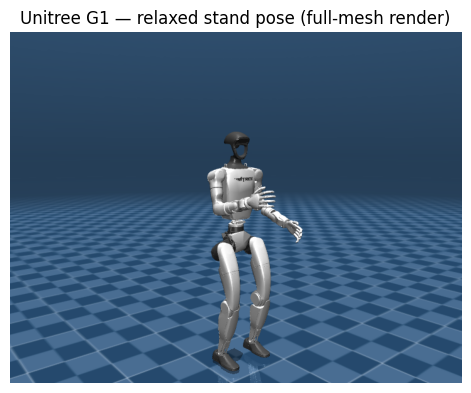

In [3]:
# Joint-name -> qpos address map for the floating-base model.
jnames = [mj.joint(i).name for i in range(mj.njnt)]
qadr = {jnames[i]: int(mj.jnt_qposadr[i]) for i in range(mj.njnt)}

# A relaxed standing pose. Base block: pelvis 0.793 m up, identity quaternion.
q_stand = np.zeros(mj.nq)
q_stand[2] = 0.793  # pelvis height z
q_stand[3] = 1.0  # quaternion w (identity orientation)
for joint, angle in [
    ("left_hip_pitch_joint", -0.25),
    ("right_hip_pitch_joint", -0.25),
    ("left_knee_joint", 0.5),
    ("right_knee_joint", 0.5),
    ("left_ankle_pitch_joint", -0.25),
    ("right_ankle_pitch_joint", -0.25),
    ("right_shoulder_pitch_joint", -0.3),
    ("right_shoulder_roll_joint", -0.15),
    ("left_shoulder_pitch_joint", 0.1),
    ("left_shoulder_roll_joint", 0.2),
    ("left_elbow_joint", 0.3),
]:
    q_stand[qadr[joint]] = angle

renderer = R.TrajectoryRenderer("unitree_g1_mjcf", g1.to_mjcf(), size=(720, 560))
showcase_still = renderer.render(
    np.array([q_stand]),
    camera=dict(distance=2.4, azimuth=140, elevation=-8, lookat=(0.0, 0.0, 0.9)),
)[0]

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(showcase_still)
ax.axis("off")
ax.set_title("Unitree G1 — relaxed stand pose (full-mesh render)")
fig.tight_layout()
plt.show()

## 2. Forward kinematics as a JAX function

We focus on the **left arm**: five joints from shoulder to wrist. Holding the
rest of the body fixed at the stand pose, define a forward-kinematics map

$$ \mathrm{FK} : \mathbb{R}^5 \;\to\; \mathbb{R}^3, \qquad
   \mathbf{q}_\text{arm} \;\mapsto\; \mathbf{x}_\text{hand}, $$

the world-frame position (in **metres**) of the left wrist body as a function of
the five arm-joint angles (in **radians**). Crucially `fk` is *ordinary JAX* —
it calls `mjx.kinematics`, so it is differentiable and `jit`-able.

In [4]:
hand = mj.body("left_wrist_yaw_link").id

arm_joints = [
    "left_shoulder_pitch_joint",
    "left_shoulder_roll_joint",
    "left_shoulder_yaw_joint",
    "left_elbow_joint",
    "left_wrist_pitch_joint",
]
arm_idx = jnp.asarray([qadr[j] for j in arm_joints])
q0 = jnp.asarray(q_stand)  # full configuration, frozen except the arm
qa_rest = q0[arm_idx]  # the arm's angles at the stand pose


def fk(qa):
    # World position (m) of the left wrist for the 5 arm angles qa (rad).
    q = q0.at[arm_idx].set(qa)
    data = mjx.make_data(mxm).replace(qpos=q)
    return mjx.kinematics(mxm, data).xpos[hand]


FK = jax.jit(fk)
print("hand position at rest pose (m):", np.round(np.asarray(FK(qa_rest)), 4))

hand position at rest pose (m): [0.1616 0.2025 0.824 ]


### `jax.jacobian(fk)` *is* the kinematic Jacobian

The kinematic Jacobian $J = \partial \mathbf{x}_\text{hand} / \partial
\mathbf{q}_\text{arm} \in \mathbb{R}^{3\times 5}$ relates joint-angle rates to
hand velocity. We do not derive or hand-code it — `jax.jacobian` differentiates
straight through MJX kinematics. To prove it is correct, we check one column
against a central finite difference $\big(\mathrm{FK}(q+\epsilon e_i) -
\mathrm{FK}(q-\epsilon e_i)\big) / 2\epsilon$.

In [5]:
jacobian = jax.jit(jax.jacobian(fk))
J = np.asarray(jacobian(qa_rest))
print("Jacobian shape:", J.shape, "(3 hand coords x 5 arm joints)")

eps = 1e-5
fd_col0 = (
    np.asarray(FK(qa_rest.at[0].add(eps))) - np.asarray(FK(qa_rest.at[0].add(-eps)))
) / (2 * eps)
print("autodiff  column 0:", np.round(J[:, 0], 6))
print("finite-diff column 0:", np.round(fd_col0, 6))
print(f"max |autodiff - finite difference| = {np.max(np.abs(J[:, 0] - fd_col0)):.2e}")

Jacobian shape: (3, 5) (3 hand coords x 5 arm joints)
autodiff  column 0: [-0.278868  0.044599 -0.1553  ]
finite-diff column 0: [-0.278868  0.044599 -0.1553  ]
max |autodiff - finite difference| = 7.01e-12


The two agree to ~$10^{-11}$ — machine precision. The Jacobian we will use for
inverse kinematics is *exact* and came for free from autodiff through the robot.

## 3. Differentiable inverse kinematics (damped least squares)

Inverse kinematics asks the opposite question: *what joint angles put the hand
at a target $\mathbf{x}^\star$?* We solve it as a least-squares problem on the
residual $\mathbf{e} = \mathbf{x}^\star - \mathrm{FK}(\mathbf{q})$. Linearising
$\mathrm{FK}$ about the current angles gives $\mathbf{e} \approx J\,\Delta
\mathbf{q}$. A raw least-squares inverse $\Delta\mathbf{q} = J^\top (JJ^\top)^{-1}
\mathbf{e}$ blows up near singular arm configurations, so we use the
**damped least squares** (Levenberg–Marquardt) step, which minimises
$\lVert J\,\Delta\mathbf{q} - \mathbf{e}\rVert^2 + \lambda^2
\lVert\Delta\mathbf{q}\rVert^2$:

$$ \Delta\mathbf{q} \;=\; J^\top \big(JJ^\top + \lambda^2 I\big)^{-1}\,\mathbf{e},
   \qquad \mathbf{q} \leftarrow \mathbf{q} + \alpha\,\Delta\mathbf{q}. $$

Here $\lambda^2 = 0.04$ (damping, $\text{m}^2$-scaled) keeps the step well-posed
and $\alpha = 0.5$ is the step size. We pick a target by evaluating `FK` at a
natural forward-up-and-out arm pose, so we know it is reachable, then iterate
from the rest pose — recording the full joint trajectory for rendering.

In [6]:
# A reachable target: the hand position of a natural "reach forward, up & out" pose.
target = FK(jnp.array([-1.1, 0.45, 0.1, 0.7, 0.0]))
print("target hand position (m):", np.round(np.asarray(target), 4))

lam2, alpha, n_iters = 0.04, 0.5, 40
qa = qa_rest
traj, dist = [], []
for _ in range(n_iters):
    q_full = np.array(q_stand)
    q_full[np.asarray(arm_idx)] = np.asarray(qa)
    traj.append(q_full)

    e = target - FK(qa)
    dist.append(float(jnp.linalg.norm(e)))
    J = jacobian(qa)
    dq = J.T @ jnp.linalg.solve(J @ J.T + lam2 * jnp.eye(3), e)
    qa = qa + alpha * dq

residual = float(jnp.linalg.norm(target - FK(qa)))
qs = np.array(traj)
print(
    f"start distance: {dist[0] * 100:.1f} cm   final residual: {residual * 1000:.2f} mm"
)

target hand position (m): [0.3487 0.212  1.1063]


start distance: 33.9 cm   final residual: 4.90 mm


The hand starts ~34 cm from the target and converges to a few-millimetre
residual (printed above). The convergence curve below shows the characteristic
fast decay of a damped-least-squares solver: large early steps, then a smooth
settle (the damping $\lambda^2$ trades a little steady-state accuracy for
robustness near singular arm configurations).

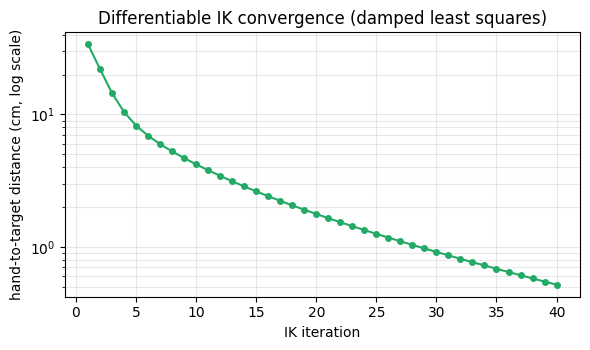

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogy(np.arange(1, n_iters + 1), np.array(dist) * 100, "o-", ms=4, color="#2a6")
ax.set_xlabel("IK iteration")
ax.set_ylabel("hand-to-target distance (cm, log scale)")
ax.set_title("Differentiable IK convergence (damped least squares)")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

## 4. Batch IK with `vmap` — the JAX scaling story

Nothing about the solver is tied to a single target. Because `fk` is pure JAX,
we can express *one* IK solve as a `jax.lax.scan` and then `jax.vmap` it across a
**batch of targets** — `jit` fuses the whole thing into one compiled kernel that
solves every reach in parallel. This is what a single pure-JAX model enables:
the differentiable model *is* the batched model.

In [8]:
def ik_solve(target, n=40):
    # Damped-least-squares IK from the rest pose; returns (angles, residual).
    def step(qa, _):
        e = target - fk(qa)
        J = jax.jacobian(fk)(qa)
        dq = J.T @ jnp.linalg.solve(J @ J.T + lam2 * jnp.eye(3), e)
        return qa + alpha * dq, None

    qa, _ = jax.lax.scan(step, qa_rest, None, length=n)
    return qa, jnp.linalg.norm(target - fk(qa))


batch_ik = jax.jit(jax.vmap(ik_solve))

# 64 reachable targets: FK of jittered natural reach poses (reachable by construction).
N = 64
key = jax.random.PRNGKey(1)
poses = jnp.array([-0.7, 0.3, 0.0, 0.6, 0.0]) + jax.random.uniform(
    key, (N, 5), minval=-0.35, maxval=0.35
)
targets = jax.vmap(fk)(poses)

_ = batch_ik(targets)[0].block_until_ready()  # compile once
t0 = time.perf_counter()
qa_batch, res_batch = batch_ik(targets)
qa_batch.block_until_ready()
dt = time.perf_counter() - t0

print(
    f"solved N = {N} independent IK reaches in {dt * 1e3:.1f} ms "
    f"({dt / N * 1e3:.2f} ms / reach) with ONE jitted vmapped function"
)
print(
    f"residuals (mm):  max {float(jnp.max(res_batch)) * 1e3:.2f}   "
    f"mean {float(jnp.mean(res_batch)) * 1e3:.2f}"
)

solved N = 64 independent IK reaches in 19.4 ms (0.30 ms / reach) with ONE jitted vmapped function
residuals (mm):  max 7.76   mean 3.07


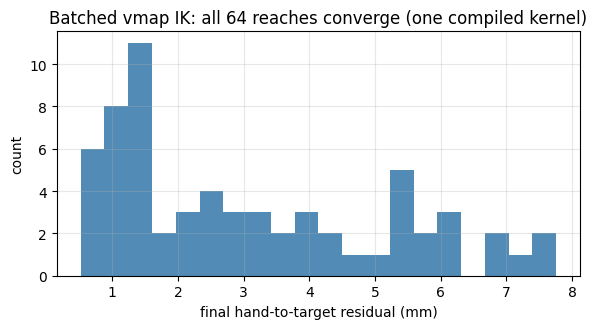

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(np.asarray(res_batch) * 1e3, bins=20, color="#37a", alpha=0.85)
ax.set_xlabel("final hand-to-target residual (mm)")
ax.set_ylabel("count")
ax.set_title(f"Batched vmap IK: all {N} reaches converge (one compiled kernel)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 5. The showcase animation — watch the arm reach

We render the IK trajectory from Section 3 through the full-mesh G1 scene and
overlay the target as a green sphere. Each frame writes one pose and calls
`mj_forward`; the motion you see is pure gradient-driven kinematics.

In [10]:
def overlay_target(scene, data, q):
    # Draw the IK target as a small green sphere (visual only).
    if scene.ngeom < scene.maxgeom:
        geom = scene.geoms[scene.ngeom]
        mujoco.mjv_initGeom(
            geom,
            mujoco.mjtGeom.mjGEOM_SPHERE,
            np.array([0.035] * 3),
            np.asarray(target, float),
            np.eye(3).flatten(),
            np.array([0.1, 0.9, 0.3, 0.95], np.float32),
        )
        scene.ngeom += 1


frames = renderer.render(
    qs,
    camera=dict(distance=1.9, azimuth=145, elevation=-6, lookat=(0.15, 0.15, 1.0)),
    overlay=overlay_target,
)
R.write_gif(frames, "examples/media/tutorial_unitree_g1.gif", width=480, fps=12)
print("wrote examples/media/tutorial_unitree_g1.gif")

wrote examples/media/tutorial_unitree_g1.gif


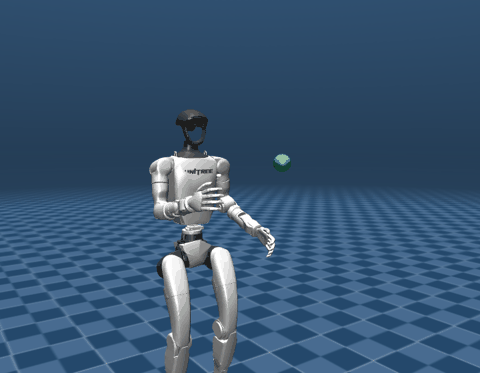

In [11]:
from IPython.display import Image

Image("examples/media/tutorial_unitree_g1.gif")

## 6. Same model, all the way to the metal

Everything above ran on **one** object, `g1`. The `fk` we differentiated, the
`vmap`ped batch solver, and (in a real pipeline) the calibrated parameters from
system identification are all attributes of the same `Robot`. That is the
sim-to-deploy guarantee: when `jaxility` compiles the controller to embedded C
for an Arm SoC, it consumes *this* model — via its `attestation_handle`, which
seals the calibrated parameters and a hash chain into the deployment manifest —
not a hand-ported copy that can silently drift from what you tested here.

In [12]:
print("This is the model jaxility would compile and attest:")
print("  attestation handle:", g1.attestation_handle is not None)
print("  provenance source: ", g1.source)

This is the model jaxility would compile and attest:
  attestation handle: True
  provenance source:  jaxterity/zoo/unitree_g1/g1.xml


## Exercises

1. **Position *and* orientation.** Extend `fk` to also return the hand's
   orientation (use `mjx.kinematics(...).xquat[hand]`), and add an orientation
   error term to the IK so the wrist reaches with a commanded pose, not just a
   point. How does the Jacobian's shape change?
2. **Reach with the whole body.** Add the three waist joints
   (`waist_yaw/roll/pitch_joint`) to `arm_idx` so the torso leans into far
   targets. Re-run the IK to a target placed *outside* the arm-only workspace
   and confirm the extra DoF let it converge.
3. **Gradients of a metric, not just of FK.** Define a scalar "reach cost"
   $C(\mathbf{q}^\star) = \lVert \mathrm{FK}(\text{IK}(\mathbf{q}^\star)) -
   \mathbf{q}^\star\rVert^2$ and take `jax.grad` of it through the *entire*
   `ik_solve` — autodiff differentiates through the solver loop, not just one FK
   call. (Hint: `jax.lax.scan` is differentiable.)

## Key takeaways

- The Unitree G1's kinematics are **pure JAX**: autodiff flows straight through
  a 29-DoF humanoid, so `jax.jacobian(fk)` *is* the kinematic Jacobian, exact to
  machine precision.
- That makes inverse kinematics a few lines of **damped least squares** — and
  `jax.vmap` turns one solve into a batch of solves in a single compiled kernel.
- The floating base means `nq = 36 ≠ nv = 35` (a quaternion carries 4 numbers,
  3 DoF); jaxterity bookkeeps this for you.
- It is the **same calibrated model** end to end — sim, batched optimisation,
  and (via the attestation handle) `jaxility`'s embedded-C deployment — which is
  only possible because it is a single pure-JAX model.